# 03 Inputs and importance: which measurements matter and how few are enough

**Question (REQ-004).** Which of the 24 magnetic measurements (16 coils `IPR01-16`, 8 flux loops `FL01-08`) matter
most, and how does the accuracy fall when fewer inputs are used?

The expensive part (network retrained for every subset on 5 folds by discharge) was run once by
`analysis/ipp1_inputs.py` and saved in `out/ipp1-inputs.json`; this notebook reads and plots it. To check the findings
independently it then re-runs a light version with a **ridge** model (seconds), with the ranking recomputed on the
training rows of every fold so the test discharges never influence which inputs are kept.

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The data live next to the repository (never inside it): HACKATHON_HOME, else the parent folder of the repository.
here = Path.cwd().resolve()
repo = next(p for p in [here, *here.parents] if (p / "analysis" / "ipp1_common.py").exists())
os.environ.setdefault("HACKATHON_HOME", str(repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import ipp1_common as C

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print("raw data folder found:", C.DATA.exists(), "| results folder found:", C.OUT.exists())

raw data folder found: True | results folder found: True


## 1. Saved network results

In [2]:
saved = json.load(open(C.OUT / "ipp1-inputs.json"))
KEY = {"saved_folds": saved["folds"], "saved_epochs": saved["epochs"]}
runs = saved["runs"]
order = ["all 24"] + [k for k in runs if k.startswith("top")] + ["IPR only (16)", "FL only (8)"]
base = runs["all 24"]["summary_nrmse_mean"]
rows = [dict(inputs=n, summary_nrmse=runs[n]["summary_nrmse_mean"], std_over_folds=runs[n]["summary_nrmse_std"], ratio_to_all_24=runs[n]["summary_nrmse_mean"] / base) for n in order]
tab = pd.DataFrame(rows).set_index("inputs")
print("summary error = mean nRMSE over the 13 targets without the limiter point and is_limited (lower is better)")
print(tab.round(4).to_string())
KEY["mlp_summary_nrmse"] = {n: round(runs[n]["summary_nrmse_mean"], 4) for n in order}
KEY["mlp_summary_nrmse_fold_std"] = {n: round(runs[n]["summary_nrmse_std"], 4) for n in order}
KEY["mlp_ratio_to_all_24"] = {n: round(runs[n]["summary_nrmse_mean"] / base, 3) for n in order}
KEY["ranking_mlp"] = saved["ranking"]

summary error = mean nRMSE over the 13 targets without the limiter point and is_limited (lower is better)
               summary_nrmse  std_over_folds  ratio_to_all_24
inputs                                                       
all 24                0.0633          0.0282           1.0000
top 16                0.0667          0.0217           1.0541
top 12                0.0775          0.0236           1.2246
top 8                 0.0943          0.0219           1.4905
top 6                 0.1429          0.0535           2.2582
top 5                 0.1565          0.0610           2.4742
top 4                 0.2036          0.0737           3.2178
top 3                 0.2647          0.0834           4.1850
top 2                 0.4036          0.0686           6.3802
IPR only (16)         0.0657          0.0316           1.0392
FL only (8)           0.2852          0.0533           4.5081


Per-target errors in physical units for some of the subsets:

In [3]:
cols = ["all 24", "top 12", "top 8", "top 6", "top 4", "IPR only (16)", "FL only (8)"]
rows = []
for t in runs["all 24"]["targets"]:
    rows.append({"target": t, "unit": runs["all 24"]["targets"][t]["unit"] or "-", **{c: runs[c]["targets"][t]["mae"] for c in cols}})
print("MAE in the unit shown, network trained on the listed inputs")
print(pd.DataFrame(rows).set_index("target").round(4).to_string())
KEY["mlp_mae_by_subset"] = {t: {c: round(runs[c]["targets"][t]["mae"], 4) for c in cols} for t in runs["all 24"]["targets"]}

MAE in the unit shown, network trained on the listed inputs
                 unit   all 24   top 12    top 8    top 6    top 4  IPR only (16)  FL only (8)
target                                                                                        
plasma_current     kA   1.4883   1.5068   1.4814   2.0794   2.9062         1.2768       6.5659
R_mag_axis         mm   0.3772   0.6290   0.9036   1.6168   2.4321         0.4918       2.3194
Z_mag_axis         mm   0.3915   0.6622   1.1689   1.5805   2.3311         0.4014       1.7160
elongation          -   0.0057   0.0063   0.0066   0.0088   0.0136         0.0055       0.0203
R_x_point          mm   0.2024   0.2673   0.4570   0.9807   1.6250         0.2838       1.4894
R_strike_point_1   mm   0.2646   0.2205   0.2629   0.8137   1.6883         0.3438       3.0254
R_limiter          mm  10.7303  11.7300  13.5058  17.0122  17.9937        12.2517      21.9421


## 2. Figures from the saved results

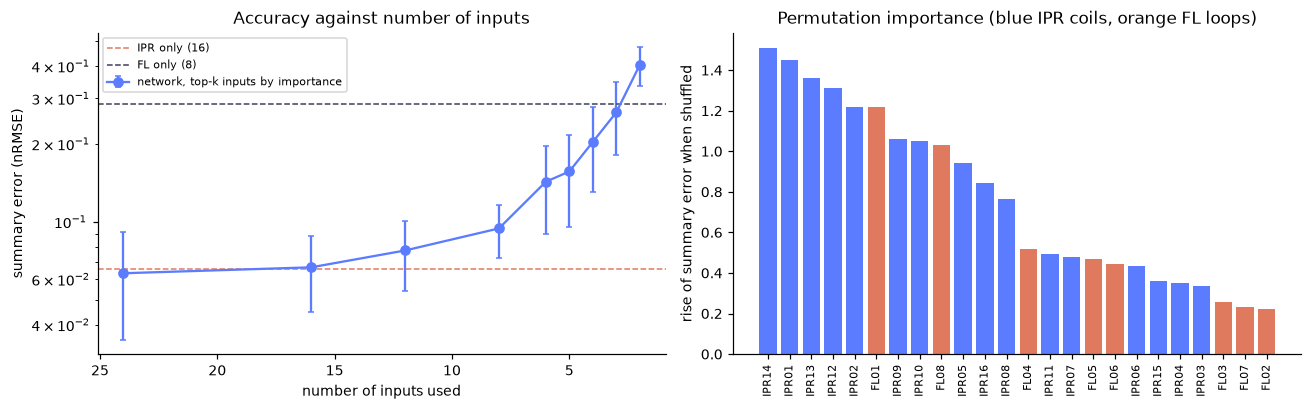

In [4]:
names = saved["inputs"]
imp = np.array([saved["permutation_importance"][n] for n in names])
ks = [24] + [int(k.split()[1]) for k in order if k.startswith("top")]
vals = [runs["all 24" if k == 24 else f"top {k}"]["summary_nrmse_mean"] for k in ks]
errs = [runs["all 24" if k == 24 else f"top {k}"]["summary_nrmse_std"] for k in ks]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].errorbar(ks, vals, yerr=errs, marker="o", color="#5b7cff", capsize=2, label="network, top-k inputs by importance")
for n, c in (("IPR only (16)", "#e07a5f"), ("FL only (8)", "#3d405b")):
    ax[0].axhline(runs[n]["summary_nrmse_mean"], color=c, ls="--", lw=1, label=n)
ax[0].set_yscale("log"); ax[0].set_xlabel("number of inputs used"); ax[0].set_ylabel("summary error (nRMSE)")
ax[0].invert_xaxis(); ax[0].legend(fontsize=7); ax[0].set_title("Accuracy against number of inputs")
o = np.argsort(-imp)
ax[1].bar(range(24), imp[o], color=["#e07a5f" if names[i].startswith("FL") else "#5b7cff" for i in o])
ax[1].set_xticks(range(24)); ax[1].set_xticklabels([names[i] for i in o], rotation=90, fontsize=7)
ax[1].set_title("Permutation importance (blue IPR coils, orange FL loops)"); ax[1].set_ylabel("rise of summary error when shuffled")
fig.tight_layout(); plt.show()

## 3. Independent light check with a linear model

For every fold: fit ridge on the training discharges, rank the inputs by permutation importance on a sample of the
**training** rows, then refit ridge on the top-k inputs and score it on the held-out discharges. We also try
a projection on the first k principal components (this still needs all 24 sensors, it only shows how much information
the sensors carry in total).

In [5]:
from scipy.stats import spearmanr
from sklearn.decomposition import PCA

df, X, Y, G, M = C.load()
folds = C.group_folds(X, Y, G, 5)
SUMMARY = [t for t in C.TARGETS if t not in ("R_limiter", "Z_limiter", "is_limited")]
summ = lambda res: float(np.mean([res[t]["nrmse"] for t in SUMMARY]))
K_LIST = [24, 16, 12, 8, 6, 5, 4, 3, 2]
rng = np.random.default_rng(0)
ridge_curve = {k: [] for k in K_LIST}
pc_curve = {k: [] for k in (1, 2, 3, 4, 5, 6, 8, 12, 24)}
fold_imp = np.zeros((5, 24))
ipr = [i for i, c in enumerate(names) if c.startswith("IPR")]
fl = [i for i, c in enumerate(names) if c.startswith("FL")]
group_runs = {"IPR only (16)": [], "FL only (8)": []}
t0 = time.time()
for f, (tr, te) in enumerate(folds):
    model = C.fit_ridge(X[tr], Y[tr], M[tr])
    sub = rng.choice(tr, size=min(6000, len(tr)), replace=False)
    b0 = summ(C.score(model(X[sub]), Y[sub], M[sub]))
    for j in range(24):
        xp = X[sub].copy()
        xp[:, j] = rng.permutation(xp[:, j])
        fold_imp[f, j] = summ(C.score(model(xp), Y[sub], M[sub])) - b0
    rank = np.argsort(-fold_imp[f])
    for k in K_LIST:
        cols_k = np.sort(rank[:k])
        m = C.fit_ridge(X[tr][:, cols_k], Y[tr], M[tr])
        ridge_curve[k].append(summ(C.score(m(X[te][:, cols_k]), Y[te], M[te])))
    for name, cols_g in (("IPR only (16)", ipr), ("FL only (8)", fl)):
        m = C.fit_ridge(X[tr][:, cols_g], Y[tr], M[tr])
        group_runs[name].append(summ(C.score(m(X[te][:, cols_g]), Y[te], M[te])))
    mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-9
    pca = PCA(24).fit((X[tr] - mu) / sd)
    ztr, zte = pca.transform((X[tr] - mu) / sd), pca.transform((X[te] - mu) / sd)
    for k in pc_curve:
        m = C.fit_ridge(ztr[:, :k].astype(np.float32), Y[tr], M[tr])
        pc_curve[k].append(summ(C.score(m(zte[:, :k].astype(np.float32)), Y[te], M[te])))
print(f"light ridge study done in {time.time() - t0:.0f} s")

rows = [dict(inputs=("all 24" if k == 24 else f"top {k}"), ridge_summary_nrmse=np.mean(v), std_over_folds=np.std(v), ratio_to_all_24=np.mean(v) / np.mean(ridge_curve[24])) for k, v in ridge_curve.items()]
rows += [dict(inputs=n, ridge_summary_nrmse=np.mean(v), std_over_folds=np.std(v), ratio_to_all_24=np.mean(v) / np.mean(ridge_curve[24])) for n, v in group_runs.items()]
rows += [dict(inputs=f"{k} principal components", ridge_summary_nrmse=np.mean(v), std_over_folds=np.std(v), ratio_to_all_24=np.mean(v) / np.mean(ridge_curve[24])) for k, v in pc_curve.items()]
rt = pd.DataFrame(rows).set_index("inputs")
print(rt.round(4).to_string())
KEY["ridge_summary_nrmse"] = {r: round(float(v), 4) for r, v in rt.ridge_summary_nrmse.items()}

light ridge study done in 25 s
                         ridge_summary_nrmse  std_over_folds  ratio_to_all_24
inputs                                                                       
all 24                                0.4630          0.0883           1.0000
top 16                                0.4673          0.0890           1.0095
top 12                                0.4694          0.0829           1.0138
top 8                                 0.4951          0.0840           1.0693
top 6                                 0.5630          0.0514           1.2161
top 5                                 0.6039          0.0729           1.3045
top 4                                 0.6388          0.0777           1.3799
top 3                                 0.7294          0.0589           1.5754
top 2                                 0.8442          0.0324           1.8236
IPR only (16)                         0.4668          0.0885           1.0084
FL only (8)                      

### Is the ranking stable, and does the linear model agree with the network?

In [6]:
imp_ridge = fold_imp.mean(0)
pair = [spearmanr(fold_imp[a], fold_imp[b]).statistic for a in range(5) for b in range(a + 1, 5)]
KEY["ridge_ranking_fold_to_fold_spearman_mean"] = float(np.mean(pair))
KEY["ridge_ranking_fold_to_fold_spearman_min"] = float(np.min(pair))
sp = spearmanr(imp, imp_ridge)
KEY["spearman_mlp_vs_ridge_importance"] = float(sp.statistic)
top_r = [names[i] for i in np.argsort(-imp_ridge)]
KEY["ranking_ridge"] = top_r
overlap = {k: len(set(saved["ranking"][:k]) & set(top_r[:k])) for k in (4, 6, 8, 12)}
KEY["top_k_overlap_mlp_ridge"] = overlap
print(f"ridge ranking, fold to fold Spearman: mean {np.mean(pair):.3f}, min {np.min(pair):.3f}")
print(f"Spearman between network importance and ridge importance: {sp.statistic:.3f}")
print("top inputs, network:", saved["ranking"][:8])
print("top inputs, ridge  :", top_r[:8])
print("overlap of the top-k sets (network vs ridge):", overlap)

ridge ranking, fold to fold Spearman: mean 0.857, min 0.788
Spearman between network importance and ridge importance: 0.460
top inputs, network: ['IPR14', 'IPR01', 'IPR13', 'IPR12', 'IPR02', 'FL01', 'IPR09', 'IPR10']
top inputs, ridge  : ['IPR09', 'IPR02', 'IPR04', 'IPR05', 'IPR01', 'FL08', 'IPR13', 'IPR11']
overlap of the top-k sets (network vs ridge): {4: 0, 6: 2, 8: 4, 12: 8}


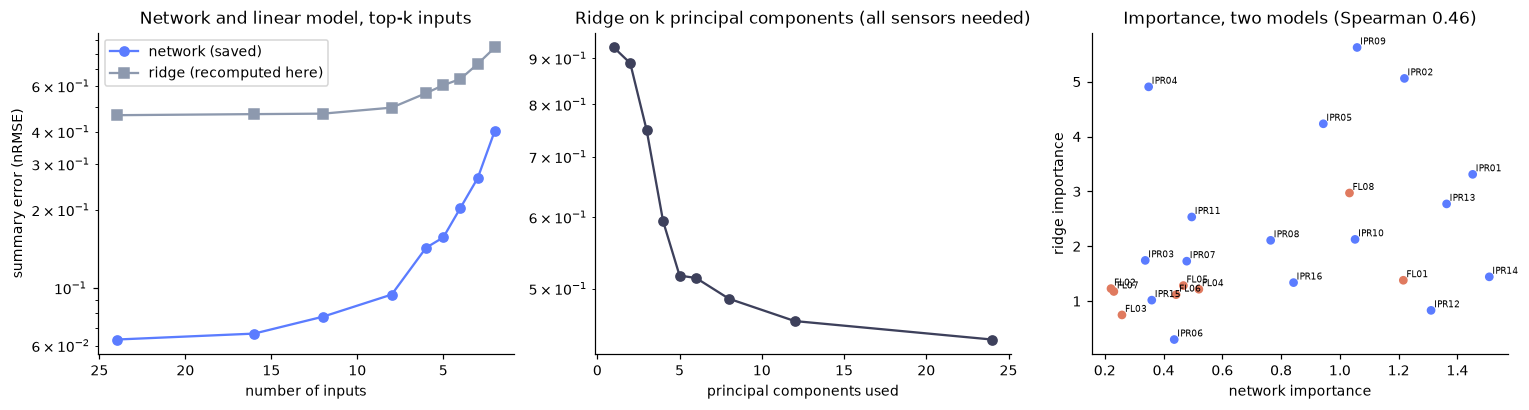

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
kk = [24] + K_LIST[1:]
ax[0].plot(ks, vals, marker="o", color="#5b7cff", label="network (saved)")
ax[0].plot(kk, [np.mean(ridge_curve[k]) for k in kk], marker="s", color="#8d99ae", label="ridge (recomputed here)")
ax[0].set_yscale("log"); ax[0].invert_xaxis(); ax[0].set_xlabel("number of inputs"); ax[0].set_ylabel("summary error (nRMSE)"); ax[0].legend()
ax[0].set_title("Network and linear model, top-k inputs")
pcs = list(pc_curve)
ax[1].plot(pcs, [np.mean(pc_curve[k]) for k in pcs], marker="o", color="#3d405b")
ax[1].set_yscale("log"); ax[1].set_xlabel("principal components used"); ax[1].set_title("Ridge on k principal components (all sensors needed)")
ax[2].scatter(imp, imp_ridge, c=["#e07a5f" if n.startswith("FL") else "#5b7cff" for n in names], s=22)
for n, a, b in zip(names, imp, imp_ridge):
    ax[2].annotate(n, (a, b), fontsize=6, xytext=(2, 2), textcoords="offset points")
ax[2].set_xlabel("network importance"); ax[2].set_ylabel("ridge importance"); ax[2].set_title(f"Importance, two models (Spearman {sp.statistic:.2f})")
fig.tight_layout(); plt.show()

## 4. How few inputs are enough?

We read off the smallest k for which the network stays within a chosen factor of the all-24 error.

In [8]:
elbow = {}
for factor in (1.25, 1.5, 2.0):
    ok = [k for k in ks if runs["all 24" if k == 24 else f"top {k}"]["summary_nrmse_mean"] <= factor * base]
    elbow[str(factor)] = int(min(ok))
KEY["smallest_k_within_factor_of_all_24"] = elbow
print("smallest number of inputs whose network error is within a factor of the all-24 error:", elbow)

smallest number of inputs whose network error is within a factor of the all-24 error: {'1.25': 12, '1.5': 8, '2.0': 8}


## 5. Key numbers (read by the conclusions below)

In [9]:
print("KEY_JSON", json.dumps(KEY))

KEY_JSON {"saved_folds": 5, "saved_epochs": 60, "mlp_summary_nrmse": {"all 24": 0.0633, "top 16": 0.0667, "top 12": 0.0775, "top 8": 0.0943, "top 6": 0.1429, "top 5": 0.1565, "top 4": 0.2036, "top 3": 0.2647, "top 2": 0.4036, "IPR only (16)": 0.0657, "FL only (8)": 0.2852}, "mlp_summary_nrmse_fold_std": {"all 24": 0.0282, "top 16": 0.0217, "top 12": 0.0236, "top 8": 0.0219, "top 6": 0.0535, "top 5": 0.061, "top 4": 0.0737, "top 3": 0.0834, "top 2": 0.0686, "IPR only (16)": 0.0316, "FL only (8)": 0.0533}, "mlp_ratio_to_all_24": {"all 24": 1.0, "top 16": 1.054, "top 12": 1.225, "top 8": 1.49, "top 6": 2.258, "top 5": 2.474, "top 4": 3.218, "top 3": 4.185, "top 2": 6.38, "IPR only (16)": 1.039, "FL only (8)": 4.508}, "ranking_mlp": ["IPR14", "IPR01", "IPR13", "IPR12", "IPR02", "FL01", "IPR09", "IPR10", "FL08", "IPR05", "IPR16", "IPR08", "FL04", "IPR11", "IPR07", "FL05", "FL06", "IPR06", "IPR15", "IPR04", "IPR03", "FL03", "FL07", "FL02"], "mlp_mae_by_subset": {"plasma_current": {"all 24": 

## Conclusions

- **The coils carry almost all the information.** The network trained on the 16 `IPR` coils alone has a summary error of 0.0657 against 0.0633 with all 24 inputs (1.04 times), while the 8 flux loops `FL` alone give 0.2852 (4.5 times worse).
- **How few are enough.** With the inputs kept by permutation importance, the summary error is 0.0667 for 16 inputs (1.05 times), 0.0775 for 12 (1.23 times), 0.0943 for 8 (1.49 times), 0.1429 for 6 (2.26 times) and 0.2036 for 4 (3.2 times). The smallest subset that stays within 1.25 times the all-24 error has 12 inputs, and within 1.5 times has 8. Below 8 inputs the error rises quickly.
- **The loss is not the same for every target.** Going from 24 to 8 inputs raises the `R_mag_axis` error from 0.38 to 0.90 mm and `R_x_point` from 0.20 to 0.46 mm, but the plasma current stays at 1.49 and 1.48 kA and the strike point `R_strike_point_1` at 0.26 and 0.26 mm.
- **The ranking depends on the model.** The network puts IPR14, IPR01, IPR13, IPR12, IPR02 first; the ridge model, with its ranking recomputed on the training rows of each fold, puts IPR09, IPR02, IPR04, IPR05, IPR01 first. The Spearman correlation of the two importance lists is 0.46 and their top-8 sets share 4 inputs (top-4 sets share 0). Inside the ridge model the ranking is stable from fold to fold (mean Spearman 0.86, lowest 0.79). Because the inputs are so redundant, several different subsets work, so the ranking should be reported as a property of the trained model and not as a physical truth.
- **The linear model is far weaker and loses less from fewer inputs.** Ridge with all 24 inputs has a summary error of 0.463, about 7.3 times the network, and with 8 inputs 0.495. Ridge on 5 principal components gives 0.517.
- **Caveats.** The network results come from one training seed per fold (fold-to-fold standard deviation of the summary error is 0.028 for 24 inputs, see the first table), and the summary leaves out the limiter point and `is_limited`.